PART B

Packages

In [1]:
import h5py
import scipy.io as io
from PIL import Image
import numpy as np
import os
import glob
from matplotlib import pyplot as plt
from scipy.ndimage.filters import gaussian_filter 
import scipy
import json
from tqdm import tqdm

from matplotlib import cm as CM
#from image import *
#%reload_ext autoreload        <------------— comment out 
#%autoreload 0                 <------------— comment out
%matplotlib inline

C:\Users\katel\AppData\Local\Temp\ipykernel_20308\1944944051.py:8: DeprecationWarning: Please use `gaussian_filter` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  from scipy.ndimage.filters import gaussian_filter


Gaussian Filter Density

In [2]:
def gaussian_filter_density(gt):
    #Generates a density map using Gaussian filter transformation
    
    density = np.zeros(gt.shape, dtype=np.float32)
    
    gt_count = np.count_nonzero(gt)
    
    if gt_count == 0:
        return density

    # FInd out the K nearest neighbours using a KDTree
    
    pts = np.array(list(zip(np.nonzero(gt)[1].ravel(), np.nonzero(gt)[0].ravel())))
    leafsize = 2048
    
    # build kdtree
    tree = scipy.spatial.KDTree(pts.copy(), leafsize=leafsize)
    
    # query kdtree
    distances, locations = tree.query(pts, k=4)

        
    for i, pt in enumerate(pts):
        pt2d = np.zeros(gt.shape, dtype=np.float32)
        pt2d[pt[1],pt[0]] = 1.
        if gt_count > 1:
            sigma = (distances[i][1]+distances[i][2]+distances[i][3])*0.1
        else:
            sigma = np.average(np.array(gt.shape))/2./2. #case: 1 point
        
        #Convolve with the gaussian filter
        
        density += scipy.ndimage.gaussian_filter(pt2d, sigma, mode='constant')
    
    return density

Folder Path

In [3]:
root = os.path.join(os.getcwd(),r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST")
print(root)

C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST


In [22]:
part_A_train = os.path.join(root,r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_A_final\train_data",'images')
part_A_test = os.path.join(root,r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_A_final\test_data",'images')
part_B_train = os.path.join(root,r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\train_data",'images')
part_B_test = os.path.join(root,r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data",'images')
path_sets = [part_B_train,part_B_test]

In [5]:
# List of all image paths
img_paths = []
for path in tqdm(path_sets):
    for img_path in glob.glob(os.path.join(path, '*.jpg')):
        img_paths.append(img_path)
print(len(img_paths))

100%|██████████| 2/2 [00:00<00:00, 246.68it/s]

716


In [7]:
from tqdm import tqdm
i = 0
for img_path in tqdm(img_paths):
           
    # Load sparse matrix
    mat = io.loadmat(img_path.replace('.jpg','.mat').replace('images','ground_truth').replace('IMG_','GT_IMG_'))
    
    #Read image
    img= plt.imread(img_path)
    
    # Create a zero matrix of image size
    k = np.zeros((img.shape[0],img.shape[1]))
    
    gt = mat["image_info"][0,0][0,0][0]
    
    #Generate hot encoded matrix of sparse matrix
    for i in range(0,len(gt)):
        if int(gt[i][1])<img.shape[0] and int(gt[i][0])<img.shape[1]:
            k[int(gt[i][1]),int(gt[i][0])]=1
    
    # generate density map
    k = gaussian_filter_density(k)
    
    # File path to save density map
    file_path = img_path.replace('.jpg','.h5').replace('images','ground')
    os.makedirs(os.path.dirname(file_path), exist_ok=True)

    with h5py.File(file_path, 'w') as hf:
            hf['density'] = k

100%|██████████| 716/716 [3:13:35<00:00, 16.22s/it]  


In [8]:
file_path = os.path.join(os.getcwd(),img_paths[22].replace('.jpg','.h5').replace('images','ground') )
print(file_path)

C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\train_data\ground\IMG_119.h5


Sum =  300.65756
C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\train_data\ground\IMG_119.h5


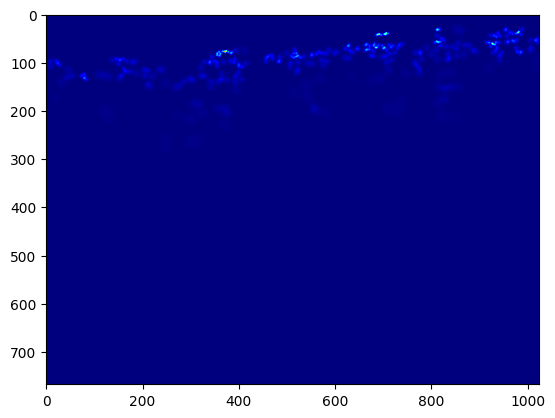

In [9]:
#Sample Ground Truth
gt_file = h5py.File(file_path,'r')
groundtruth = np.asarray(gt_file['density'])
plt.imshow(groundtruth,cmap=CM.jet)
print("Sum = " ,np.sum(groundtruth))
print(file_path)

C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\train_data\ground\IMG_119.h5


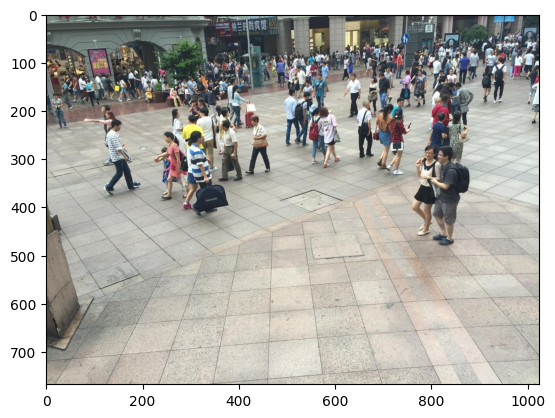

In [11]:
# Image corresponding to the ground truth
img = Image.open(file_path.replace('.h5','.jpg').replace('ground','images'))
plt.imshow(img)
print(file_path)

In [12]:
os.getcwd()

'c:\\Users\\katel\\OneDrive\\Documents\\OneDrive\\Desktop'

In [13]:
len(gt)

113

In [14]:
print(k)

[[0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 0.0000000e+00
  0.0000000e+00 0.0000000e+00]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 0.0000000e+00
  0.0000000e+00 0.0000000e+00]
 [0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 0.0000000e+00
  0.0000000e+00 0.0000000e+00]
 ...
 [7.3202764e-06 7.3320216e-06 7.3424007e-06 ... 1.7773458e-05
  1.7572180e-05 1.7370006e-05]
 [7.1530799e-06 7.1645568e-06 7.1746990e-06 ... 1.7488357e-05
  1.7290360e-05 1.7091483e-05]
 [6.9883831e-06 6.9995958e-06 7.0095048e-06 ... 1.7205335e-05
  1.7010592e-05 1.6814985e-05]]


In [17]:
pts = np.array(list(zip(np.nonzero(k)[1].ravel(), np.nonzero(k)[0].ravel())))


In [18]:
pts.shape

(562318, 2)

In [19]:
i=int(0)
for pt in pts:
    print(pt)
    i+=1
    if i==50:
        break

[790  40]
[791  40]
[792  40]
[793  40]
[794  40]
[795  40]
[796  40]
[797  40]
[798  40]
[799  40]
[800  40]
[801  40]
[802  40]
[803  40]
[804  40]
[805  40]
[806  40]
[807  40]
[808  40]
[809  40]
[810  40]
[811  40]
[812  40]
[813  40]
[814  40]
[815  40]
[816  40]
[817  40]
[818  40]
[819  40]
[820  40]
[821  40]
[822  40]
[823  40]
[824  40]
[825  40]
[826  40]
[827  40]
[828  40]
[829  40]
[830  40]
[831  40]
[832  40]
[833  40]
[834  40]
[835  40]
[836  40]
[837  40]
[838  40]
[839  40]
